# Project Assignment 1

Time Series and Forecasting

In [1]:
## Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose

## Plot definitions
plt.style.use('ggplot')
pd.set_option('display.max_columns', 30)

In [2]:
## Load Data
project_dir = Path.cwd().parent
data_dir = project_dir / 'data'

main_series = (data_dir / 'olim-month-of-year-1989-2023.csv')
raw_df1 = pd.read_csv(main_series)

second_series = (data_dir / 'data_gpr_month.xls')
raw_df2 = pd.read_excel(second_series)



## 1. Description of the Selected Time Series and Their Expected Relationship

#### Main Series - New Olim by Month and Year : 
A breakdown of the number of immigrants (Olim) in each month over 1989-2023

#### Exogenic Series - GPR specefic country : !!!!!!! NEED TO MODIFY BE SELECTED COUNTRY
The country-specific GPR indexes are based on searches of newspaper archives. For 44 advanced and emerging countries, Caldara and Iacoviello calculate the country-specific index by counting the monthly share of all newspaper articles from 1900 to present (or 1985 to present for the Recent Index) that both :

(1) meet the criterion for inclusion in the GPR index

and

(2) mention the name of the country or its major cities. 

Each index is expressed as a monthly share of newspaper articles. The resulting indices capture the U.S. perspective on risks posed by, or involving, the country in question.


#### Expected Relationship : !!!!!!! NEED TO MODIFY BE SELECTED COUNTRY

*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 2. Raw Data Sources

#### Main Series - New Olim by Month and Year - 
https://data.gov.il/he/datasets/ministry_of_immigrant_absorption/new-olim-by-month

#### Exogenic Series - GPR specefic country : !!!!!!! NEED TO MODIFY BE SELECTED COUNTRY
https://www.matteoiacoviello.com/gpr_country.htm

In [3]:
raw_df1.head(n=20)

,year,month,olim
0,1989,1,1116
1,1989,2,1156
2,1989,3,1761
3,1989,4,1154
4,1989,5,1528
5,1989,6,1201
6,1989,7,1772
7,1989,8,2158
8,1989,9,2227
9,1989,10,2795


In [4]:
raw_df2.head(n=20)

,month,GPR,GPRT,GPRA,GPRH,GPRHT,GPRHA,SHARE_GPR,N10,SHARE_GPRH,N3H,GPRH_NOEW,GPR_NOEW,GPRH_AND,GPR_AND,...,GPRHC_PRT,GPRHC_RUS,GPRHC_SAU,GPRHC_SWE,GPRHC_THA,GPRHC_TUN,GPRHC_TUR,GPRHC_TWN,GPRHC_UKR,GPRHC_USA,GPRHC_VEN,GPRHC_VNM,GPRHC_ZAF,var_name,var_label
0,1900-01-01,NaN,NaN,NaN,87.927849,64.717491,110.453522,NaN,NaN,3.171932,7724,92.189819,NaN,116.949104,NaN,...,0.245987,0.258933,0.0,0.012947,0.077680,0.000000,0.038840,0.000000,0.0,2.718799,0.051787,0.012947,1.152253,month,Date (year/month)
1,1900-02-01,NaN,NaN,NaN,86.566490,71.936844,96.250488,NaN,NaN,3.122822,7173,91.032326,NaN,131.074982,NaN,...,0.139412,0.334588,0.0,0.000000,0.083647,0.000000,0.125471,0.000000,0.0,2.732469,0.027882,0.000000,1.143176,GPR,Recent GPR (Index: 1985:2019=100)
2,1900-03-01,NaN,NaN,NaN,72.140701,57.475853,84.499428,NaN,NaN,2.602422,7762,77.067757,NaN,112.938850,NaN,...,0.051533,0.386498,0.0,0.012883,0.115949,0.000000,0.180366,0.000000,0.0,2.151507,0.025767,0.000000,0.863180,GPRT,Recent GPR Threats (Index: 1985:2019=100)
3,1900-04-01,NaN,NaN,NaN,54.419449,37.326603,65.858208,NaN,NaN,1.963141,7488,61.985249,NaN,99.778038,NaN,...,0.080128,0.267094,0.0,0.000000,0.040064,0.000000,0.066774,0.000000,0.0,1.776175,0.000000,0.000000,0.641026,GPRA,Recent GPR Acts (Index: 1985:2019=100)
4,1900-05-01,NaN,NaN,NaN,64.405197,48.200008,74.373955,NaN,NaN,2.323370,7360,64.238335,NaN,105.352043,NaN,...,0.081522,0.176630,0.0,0.000000,0.163043,0.000000,0.081522,0.000000,0.0,1.970109,0.013587,0.000000,0.788043,GPRH,Historical GPR (Index: 1900:2019=100)
5,1900-06-01,NaN,NaN,NaN,83.610252,70.006577,93.977692,NaN,NaN,3.016178,7294,77.467339,NaN,124.273941,NaN,...,0.068549,0.945983,0.0,0.013710,0.082259,0.013710,0.109679,0.027420,0.0,2.728270,0.027420,0.041130,0.671785,GPRHT,Historical GPR Threats (Index: 1900:2019=100)
6,1900-07-01,NaN,NaN,NaN,108.571121,87.062378,125.709084,NaN,NaN,3.916622,7532,95.879486,NaN,134.726196,NaN,...,0.039830,1.035581,0.0,0.013277,0.252257,0.000000,0.146044,0.039830,0.0,3.544875,0.026553,0.026553,0.292087,GPRHA,Historical GPR Acts (Index: 1900:2019=100)
7,1900-08-01,NaN,NaN,NaN,108.502815,63.841644,149.760986,NaN,NaN,3.914158,7409,95.914795,NaN,126.370201,NaN,...,0.026994,1.106762,0.0,0.040491,0.242948,0.013497,0.080983,0.040491,0.0,3.549737,0.026994,0.013497,0.242948,SHARE_GPR,Percent of Recent GPR Articles
8,1900-09-01,NaN,NaN,NaN,62.813301,54.698414,67.581779,NaN,NaN,2.265943,7370,65.520256,NaN,108.190735,NaN,...,0.094980,0.786974,0.0,0.000000,0.135685,0.000000,0.040706,0.013569,0.0,2.008141,0.013569,0.000000,0.176391,N10,"Number of articles (10 recent newspapers, 1985-)"
9,1900-10-01,NaN,NaN,NaN,43.366932,31.717627,51.432850,NaN,NaN,1.564430,7287,46.683296,NaN,88.744675,NaN,...,0.013723,0.178400,0.0,0.013723,0.068615,0.000000,0.027446,0.000000,0.0,1.262522,0.000000,0.000000,0.205846,SHARE_GPRH,Percent of Historical GPR Articles


*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 3. Description of the Processing Applied to the Time Series

In [5]:
### df1 Processing

df1 = raw_df1[ raw_df1["year"] >= 2000 ]["olim"].reset_index(drop=True) # selecting 2000-2023 range
df1

0      4921
1      4443
2      4624
3      4180
4      4500
       ... 
283    4785
284    2375
285    1173
286    1456
287    2129
Name: olim, Length: 288, dtype: int64

In [10]:
### df2 Processing
df2 = raw_df2[ (raw_df2['month'].dt.year >= 2000) & (raw_df2['month'].dt.year < 2024) ] \
    .filter(like='GPRC') \
    .reset_index(drop=True)

country="RUS"

df2 = df2.filter(like=country)
print(df2)

     GPRC_RUS
0    0.731371
1    0.534126
2    0.350368
3    0.440753
4    0.466002
..        ...
283  1.965781
284  1.905741
285  1.839135
286  1.270417
287  1.499743

[288 rows x 1 columns]


In [11]:
# Write your code here if it is relevant to this section.
# You may add more code cells as needed.

*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 4. Rationale for the Data Processing Choices

In [12]:
# Write your code here if it is relevant to this section.
# You may add more code cells as needed.

*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 5. Final Data File (CSV)

In [27]:
final_df = pd.concat([df1, df2], axis=1)
final_df

,olim,GPRC_RUS
0,4921,0.731371
1,4443,0.534126
2,4624,0.350368
3,4180,0.440753
4,4500,0.466002
...,...,...
283,4785,1.965781
284,2375,1.905741
285,1173,1.839135
286,1456,1.270417


*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 6. Initial Analysis of the Main Time Series and Its Decomposition into Components

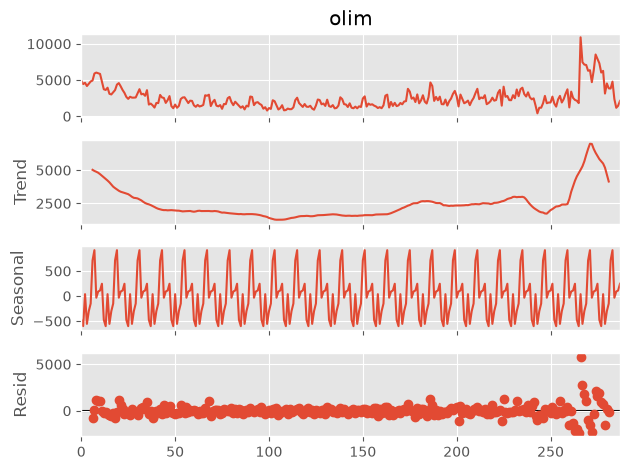

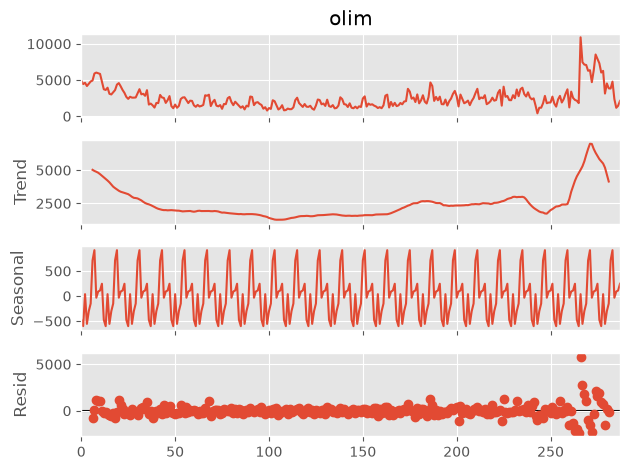

In [29]:
monthly = 12

result = seasonal_decompose(df1, model="additive", period=monthly)

result.plot()

*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*